Retrieval直接翻译过来即“检索”，本章Retrieval模块包括与检索步骤相关的所有内容，例如数据的获取、切分、向量化、向量存储、向量检索等模块。

官方文档地址：https://docs.langchain.com/oss/python/langchain/retrieval

## 1、大模型的局限

1）**知识滞后**
LLM 训练数据有截止日期 ，无法及时反映 最新的信息 或动态变化。比如：难以应对诸如“请推荐当前热门影片”等时间敏感性问题。

2）**知识缺失**
大型语言模型（LLM）的训练依赖于网络上 海量公开的静态数据 ，而某些 特定领域 （如企业内部资料、专有技术文档等）或 你的私有数据 是缺乏的，导致模型回复时生成不准确甚至虚构的回复。

3）**幻觉**
LLM 在生成回答时，可能会 “胡言乱语” ，这种现象称之为 LLM 的“幻觉”。“幻觉”可以体现为错误陈述、编造事实、错误的复杂推理或者复杂语境下理解能力不足等。

幻觉问题的严重性：大模型生成内容的不可控，尤其是在 金融 和 医疗领域 等领域， 一次金额评估的错误，一次医疗诊断的失误，哪怕只出现一次都是致命的 。但，对于非专业人士来说可能难以辨识。目前还没有能够百分之百解决这种情况的方案。

幻觉产生的原因：
- **训练知识存在偏差** ，这些**错误信息**被 LLM 学习后在输出中复现
- LLM 训练时**过度泛化** ，将普通的模式应用在 **特定场合** 导致不准确输出
- LLM 本身没有真正学习到训练数据中 **深层次的含义** ，导致在一些需要深入理解或 **复杂推理** 的任务中出错
- LLM **缺乏某些领域的相关知识** ，在面临这些领域的相关问题时编造不存在的信息

当前大家普遍达成共识的一个方案：首先，为大模型提供一定的上下文信息，让其输出会变得更稳定。其次，利用本章的RAG，将检索出来的 **文档和提示词** 输送给大模型，生成更可靠的答案。

## 2、什么是RAG

RAG（Retrieval-Augmented Generation，检索增强生成）是一种结合**信息检索**（Retrieval）与**文本生成**（Generation）的技术，旨在提升大语言模型在回答专业问题时的准确性和可靠性。

典型的检索流程如下：（官方）

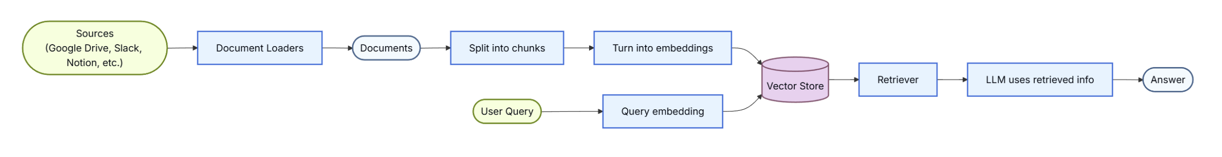

即：

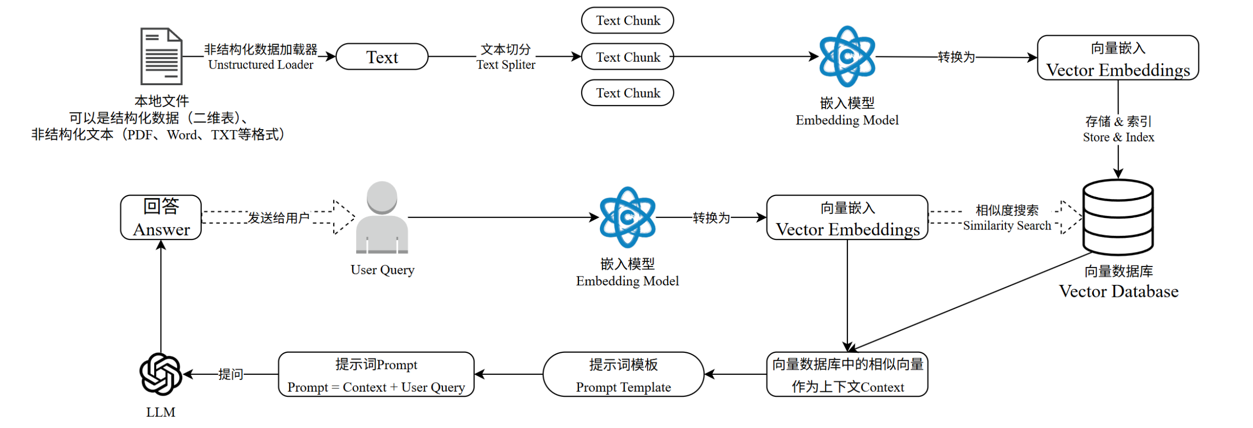

简单举例：

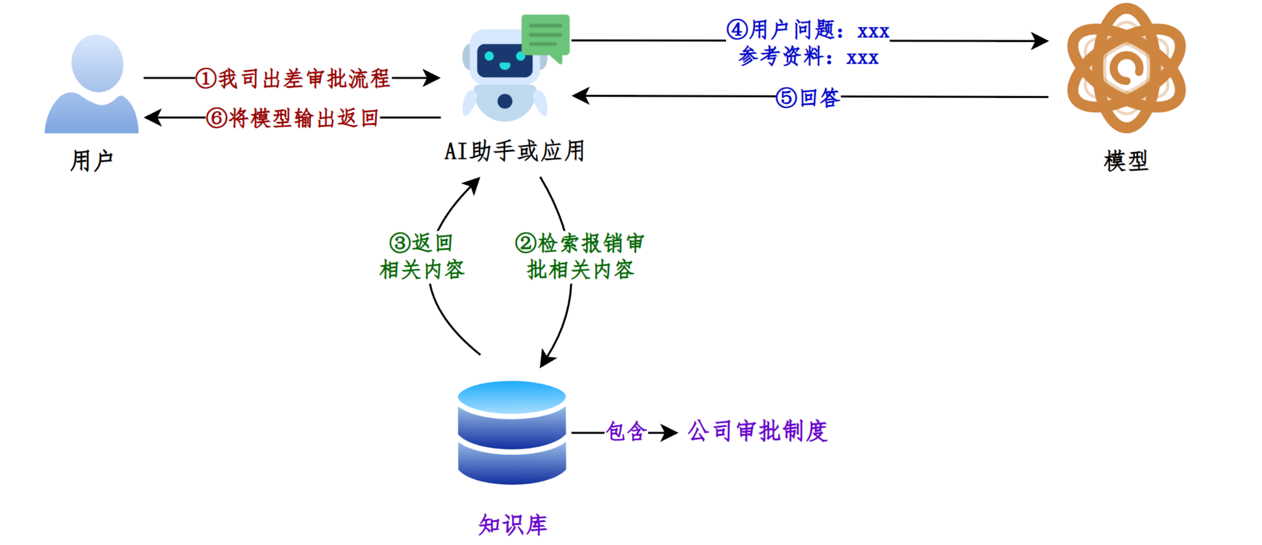

> 如果说LangChain相当于给LLM这个“大脑”安装了“四肢和躯干”，RAG则是为LLM提供了接入“人类知识图书馆”的能力。

RAG的项目举例：

目前，已经出现了非常多的产品几乎完全建立在 RAG 之上，包括 客服系统 、 基于大模型的数据分析 ，以及成千上万的数据驱动 聊天应用 ，应用场景五花八门。

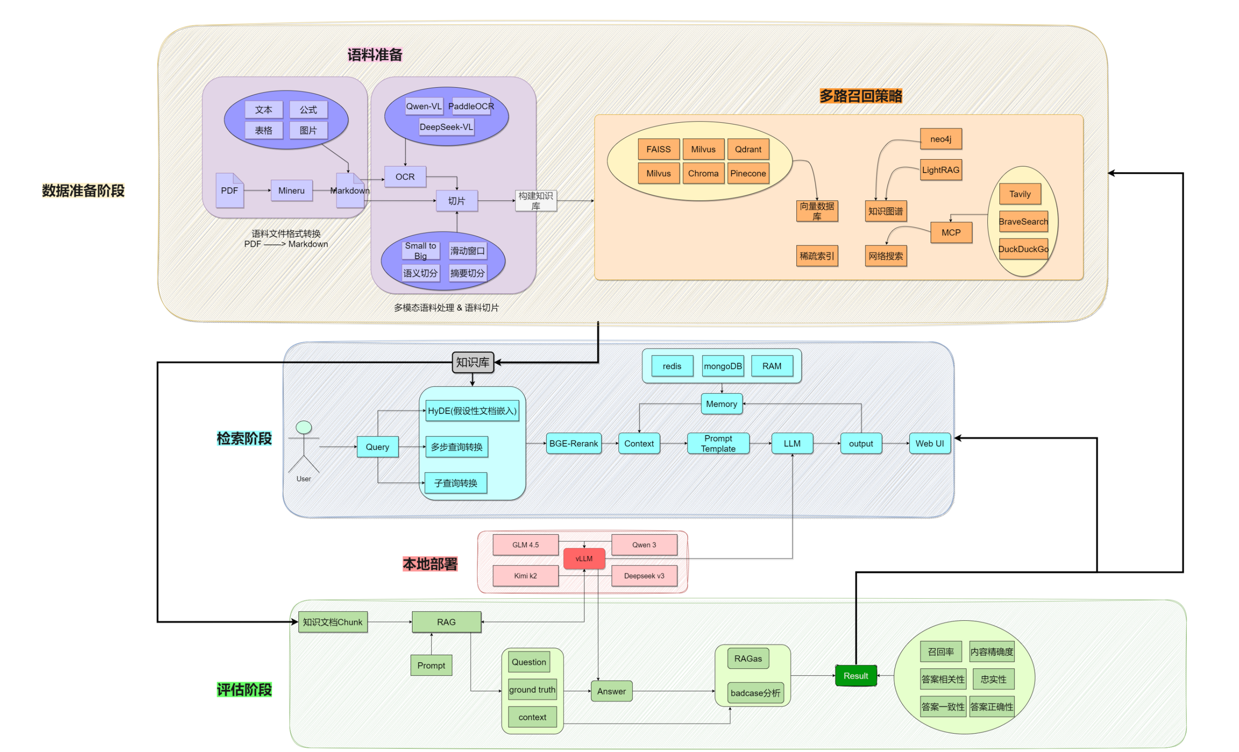

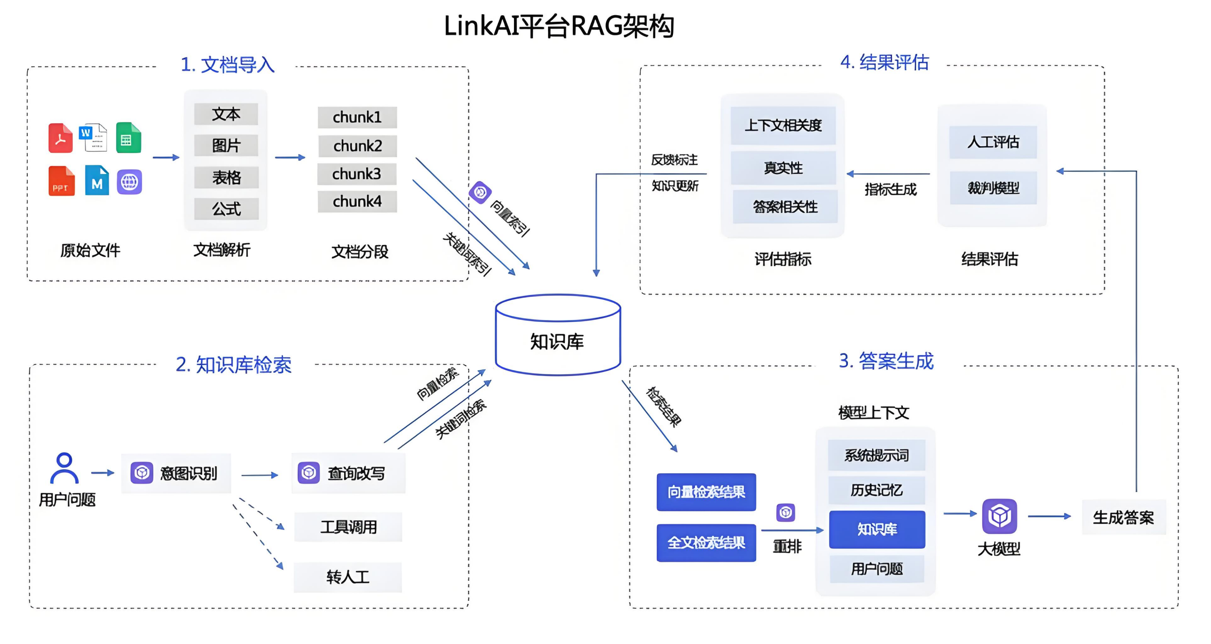

## 3、RAG优缺点

优点：
- 相比提示词工程，RAG有更丰富的上下文和数据样本，可以不需要用户提供过多的背景描述，就能生成比较符合用户预期的答案。
- 相比于模型微调，RAG可以提升问答内容的时效性和可靠性。
- 在一定程度上保护了业务数据的隐私性。

缺点：
- 由于每次问答都设计外部系统数据检索，因此RAG的响应延时相对较高。
- 引用的外部知识数据会消耗大量的模型token资源。


## 4、RAG工作流程

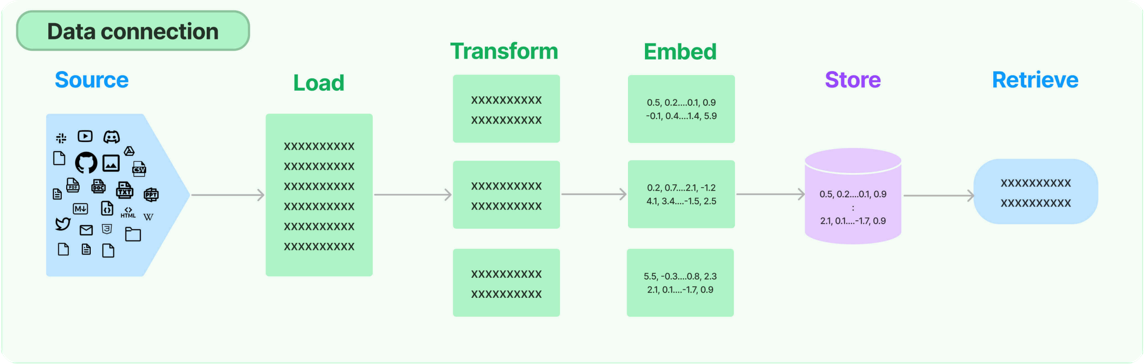

**环节1: Source（数据源）**

指的是RAG架构中所外挂的知识库。
- 原始数据源类型多样：如：视频、图片、文本、代码、文档等
- 形式的多样性：
    - 可以是上百个.csv文件，可以是上千个.json文件，也可以是上万个.pdf文件
    - 可以是某一个业务流程外放的API，可以是某个网站的实时数据等

**环节2：Load（加载）**

文档加载器（Document Loaders）负责将来自不同数据源的非结构化文本，加载到 内存 ，成为 文档(Document)对象 。

文档对象包含 文档内容 和相关 元数据信息 ，例如TXT、CSV、HTML、JSON、Markdown、PDF，甚至 YouTube 视频转录等。

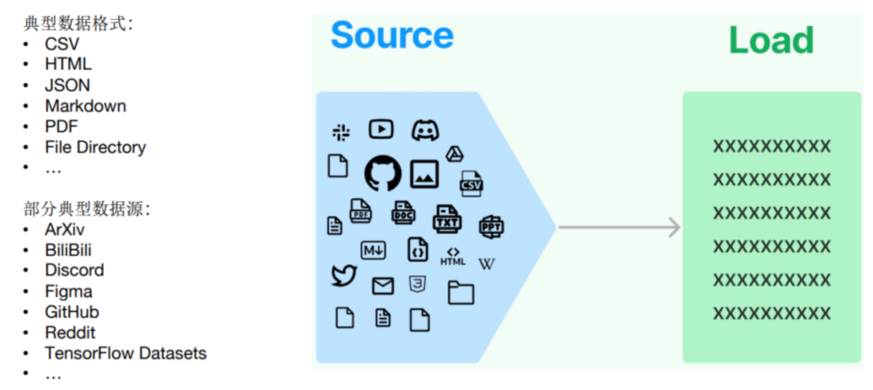

文档加载器还支持“ 延迟加载 ”模式，以缓解处理大文件时的内存压力。

LangChain封装好的loader地址：https://docs.langchain.com/oss/python/integrations/document_loaders

文档加载器的编程接口使用起来非常简单，以下给出加载TXT格式文档的例子。
```
from langchain.document_loadersimport TextLoader

loader = TextLoader("./test.txt")
print(loader.load())
```

**环节3：Transform（转换）**

文档转换器(Document Transformers) 负责对加载的文档进行转换和处理，以便更好地适应下游任务的需求。

文档转换器提供了一致的接口（工具）来操作文档，主要包括以下几类：
- 文本拆分器(Text Splitters) ：将长文本拆分成语义上相关的小块，以适应语言模型的上下文窗口限制。
- 冗余过滤器(Redundancy Filters) ：识别并过滤重复的文档。
- 元数据提取器(Metadata Extractors) ：从文档中提取标题、语调等结构化元数据。
- 多语言转换器(Multi-lingual Transformers) ：实现文档的机器翻译。
- 对话转换器(Conversational Transformers) ：将非结构化对话转换为问答格式的文档。

总的来说，文档转换器是 LangChain 处理管道中非常重要的一个组件，它丰富了框架对文档的表示和操作能力。

在这些功能中，文档拆分器是必须的操作。下面单独说明。

**环节3.1：Text Splitting（文档拆分）**
- 拆分/分块的必要性 ：前一个环节加载后的文档对象可以直接传入文档拆分器进行拆分，而文档切块后才能 向量化 并存入数据库中。
- 文档拆分器的多样性 ：LangChain提供了丰富的文档拆分器，不仅能够切分普通文本，还能切分Markdown、JSON、HTML、代码等特殊格式的文本。
- 拆分/分块的挑战性 ：实际拆分操作中需要处理许多细节问题， 不同类型的文本 、 不同的使用场景 都需要采用不同的分块策略。（具体策略见2.3.2）

在构建RAG应用程序的整个流程中，拆分/分块是最具挑战性的环节之一，它显著影响检索效果。目前还没有通用的方法可以明确指出哪一种分块策略最为有效。不同的使用场景和数据类型都会影响分块策略的选择。

**环节4：Embed（嵌入）**

文档嵌入模型（Text Embedding Models）负责将 文本 转换为 向量表示 ，即模型赋予了文本计算机可理解的数值表示，使文本可用于向量空间中的各种运算，大大拓展了文本分析的可能性，是自然语言处理领域非常重要的技术。
- 实现原理：通过 特定算法 （如Word2Vec）将语义信息编码为固定维度的向量，具体算法细节需后续深入。
- 关键特性：相似的词在向量空间中距离相近，例如"猫"和"犬"的向量夹角小于"猫"和"汽车"。

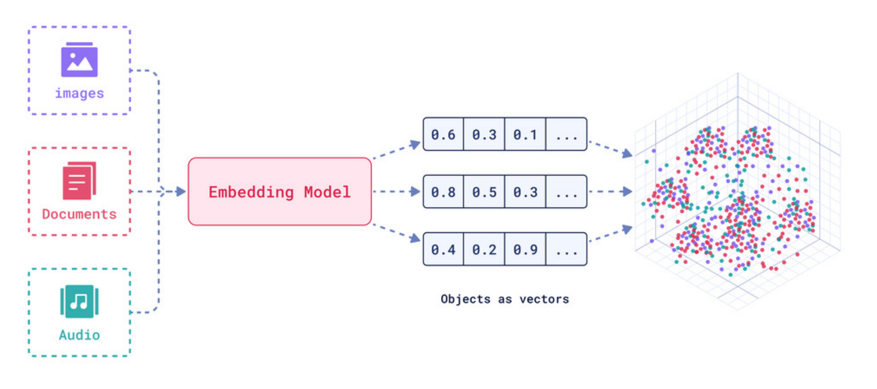

文本嵌入为 LangChain 中的问答、检索、推荐等功能提供了重要支持。具体为：
- 语义匹配 ：通过计算两个文本的向量余弦相似度，判断它们在语义上的相似程度，实现语义匹配。
- 文本检索 ：通过计算不同文本之间的向量相似度，可以实现语义搜索，找到向量空间中最相似的文本。
- 信息推荐 ：根据用户的历史记录或兴趣嵌入生成用户向量，计算不同信息的向量与用户向量的相似度，推荐相似的信息。
- 知识挖掘 ：可以通过聚类、降维等手段分析文本向量的分布，发现文本之间的潜在关联，挖掘知识。
- 自然语言处理 ：将词语、句子等表示为稠密向量，为神经网络等下游任务提供输入。

**环节5：Store（存储）**

LangChain 还支持把文本嵌入存储到向量存储或临时缓存，以避免需要重新计算它们。这里就出现了数据库，支持这些嵌入的高效 存储 和 搜索 的需求。

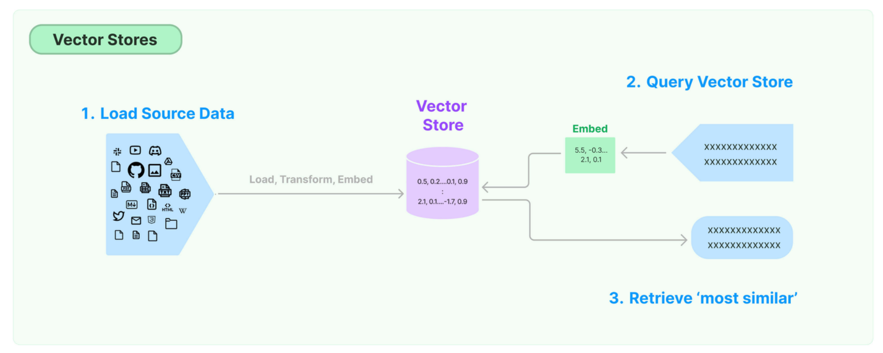

**环节6：Retrieve（检索）**

检索器（Retrievers）是一种用于 响应非结构化查询 的接口，它可以返回符合查询要求的文档。LangChain 提供了一些常用的检索器，如 向量检索器 、 文档检索器 、 网站研究检索器 等。

通过配置不同的检索器，LangChain 可以灵活地平衡检索的精度、召回率与效率。检索结果将为后续的问答生成提供信息支持，以产生更加准确和完整的回答。